# 🐍 Python Libraries for Beginners
### NumPy · Pandas · Matplotlib · Web Scraping

This notebook introduces four of the most useful Python libraries. Each section has a short explanation, runnable examples, and a small practice exercise.

**How to use this notebook**
- Run a cell with **Shift + Enter**, or the ▶ button on its left.
- Run the cells **in order**, from top to bottom.
- Change the code and run it again. Experimenting is the best way to learn!

**Contents**
1. NumPy – fast number crunching
2. Pandas – working with tables of data
3. Matplotlib – drawing charts
4. Web Scraping – collecting data from websites
5. Mini Project – putting it all together

## ⚙️ Setup
Google Colab already has all these libraries installed. On your own computer you would install them with:
```
pip install numpy pandas matplotlib requests beautifulsoup4
```
We import each library once with a short nickname (`np`, `pd`, `plt`). These nicknames are a convention that almost every Python programmer uses.

In [ ]:
import numpy as np                 # numbers and arrays
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # charts
import requests                    # downloading web pages
from bs4 import BeautifulSoup      # reading HTML
import time                        # adding pauses

print("All libraries loaded! ✅")

All libraries loaded! ✅


---
# 1️⃣ NumPy – Fast Number Crunching

**NumPy** (Numerical Python) gives us the **array**: a list of numbers that can do maths on every item at once. It is much faster than a normal Python list, and pandas, Matplotlib and most AI libraries are built on top of it.

### 1.1 Creating arrays

In [ ]:
# Make an array from a normal Python list
marks = np.array([78, 92, 65, 88, 54, 95, 71])
print("Marks:", marks)
print("Shape:", marks.shape)   # (7,) means 7 items in one row
print("Type :", marks.dtype)   # the data type of the items

# Other handy ways to create arrays
print("Zeros        :", np.zeros(5))             # five 0s
print("Range        :", np.arange(0, 20, 5))     # start, stop, step -> 0 5 10 15
print("Evenly spaced:", np.linspace(0, 1, 5))    # 5 numbers from 0 to 1

Marks: [78 92 65 88 54 95 71]
Shape: (7,)
Type : int64
Zeros        : [0. 0. 0. 0. 0.]
Range        : [ 0  5 10 15]
Evenly spaced: [0.   0.25 0.5  0.75 1.  ]


### 1.2 Vectorized maths – no loops needed!
With a list you would need a `for` loop to change every item. With an array you write the maths once and NumPy applies it to every item.

In [ ]:
print("Add 5 bonus marks :", marks + 5)
print("Percent out of 120:", (marks / 120 * 100).round(1))

# ⚠️ Watch the difference between a list and an array
python_list = [78, 92, 65]
print("\nList  * 2:", python_list * 2)            # repeats the list!
print("Array * 2:", np.array(python_list) * 2)   # doubles each number

Add 5 bonus marks : [ 83  97  70  93  59 100  76]
Percent out of 120: [65.  76.7 54.2 73.3 45.  79.2 59.2]

List  * 2: [78, 92, 65, 78, 92, 65]
Array * 2: [156 184 130]


### 1.3 Quick statistics

In [ ]:
print("Average :", marks.mean())
print("Highest :", marks.max())
print("Lowest  :", marks.min())
print("Std dev :", marks.std().round(2))   # how spread out the marks are

Average : 77.57142857142857
Highest : 95
Lowest  : 54
Std dev : 14.03


### 1.4 Filtering with conditions
`marks >= 70` gives a list of True/False values. Putting that inside `marks[...]` keeps only the True items. This is called **boolean indexing**.

In [ ]:
print("True/False check:", marks >= 70)
print("Passed (>= 70)  :", marks[marks >= 70])
print("Number failed   :", np.sum(marks < 60))   # True counts as 1

### 1.5 2D arrays (rows and columns)
Think of a 2D array as a grid. Here, each **row** is a student and each **column** is a subject.
- `axis=1` means work **across each row** (per student).
- `axis=0` means work **down each column** (per subject).

In [ ]:
scores = np.array([
    [80, 75, 90, 85],   # Student A
    [60, 70, 65, 72],   # Student B
    [95, 88, 92, 98],   # Student C
])
print(scores)
print("\nEach student's average:", scores.mean(axis=1).round(1))
print("Each subject's average:", scores.mean(axis=0).round(1))
print("Student C, subject 2  :", scores[2, 1])   # row 2, column 1 (counting from 0)

### 1.6 Random numbers
Random numbers are useful for games, simulations and test data. `np.random.seed()` makes the "random" results the same every time, which helps when teaching.

In [ ]:
np.random.seed(42)
dice = np.random.randint(1, 7, size=1000)   # 1000 rolls of a 6-sided die
print("First 10 rolls:", dice[:10])
print("Average of 1000 rolls:", dice.mean())   # should be close to 3.5

### ✏️ Practice: NumPy
1. Create an array of temperatures for 7 days: `[22, 25, 19, 30, 28, 24, 21]`.
2. Convert them to Fahrenheit using `F = C * 9/5 + 32`.
3. Print only the days hotter than 24°C.

In [ ]:
# Write your answer here

---
# 2️⃣ Pandas – Working With Tables of Data

**Pandas** gives us the **DataFrame**: a table with rows and columns, like an Excel sheet inside Python. It is the most used tool for data analysis.

- A **DataFrame** is the whole table.
- A **Series** is a single column.

### 2.1 Creating a DataFrame

In [ ]:
data = {
    "product":  ["Pen", "Notebook", "Bag", "Pen", "Bag", "Notebook", "Pen", "Bottle"],
    "category": ["Stationery", "Stationery", "Accessories", "Stationery",
                 "Accessories", "Stationery", "Stationery", "Accessories"],
    "price":    [10, 50, 500, 10, 450, 55, 12, 200],
    "quantity": [100, 40, 5, 80, 8, 30, 120, 15],
    "city":     ["Delhi", "Mumbai", "Delhi", "Mumbai", "Pune", "Delhi", "Pune", "Mumbai"],
}
df = pd.DataFrame(data)
df   # the last line of a cell is displayed as a nice table in Colab

### 2.2 Saving and loading CSV files
Real data usually comes as a **CSV** file (comma-separated values). In Colab you can see saved files in the 📁 panel on the left.

In [ ]:
df.to_csv("sales.csv", index=False)   # save to a file
df = pd.read_csv("sales.csv")         # load it back
print("Loaded", len(df), "rows from sales.csv")

### 2.3 Looking at the data

In [ ]:
print("Shape (rows, columns):", df.shape)
print("Column names:", list(df.columns))
df.head(3)   # first 3 rows

In [ ]:
df.describe()   # quick statistics for every number column

### 2.4 Selecting columns
- One column → single brackets: `df["price"]`
- Several columns → double brackets: `df[["product", "price"]]`

In [ ]:
df[["product", "price"]]

### 2.5 Adding a new column
Column maths works just like NumPy: it is applied to every row at once.

In [ ]:
df["revenue"] = df["price"] * df["quantity"]
df

### 2.6 Filtering rows
Use a condition inside `df[...]`. To combine conditions use `&` (and) or `|` (or), and wrap each condition in brackets.

In [ ]:
print("Items costing more than 100:")
display(df[df["price"] > 100])

print("Stationery sold in Delhi:")
display(df[(df["city"] == "Delhi") & (df["category"] == "Stationery")])

### 2.7 Sorting

In [ ]:
# Top 3 rows by revenue
df.sort_values("revenue", ascending=False).head(3)

### 2.8 Group by – the superpower of pandas
`groupby` splits the table into groups, does a calculation on each group, and combines the results. It answers questions like *"What is the total revenue in each city?"*

In [ ]:
df.groupby("city")["revenue"].sum()

In [ ]:
# Several calculations at once, with our own column names
df.groupby("category").agg(
    total_revenue=("revenue", "sum"),
    avg_price=("price", "mean"),
    items_sold=("quantity", "sum"),
)

### 2.9 Handling missing data
Real data often has empty cells, which pandas shows as `NaN` (Not a Number). We can find them and fill them in.

In [ ]:
df.loc[2, "price"] = None                      # pretend one price is missing
print("Missing values per column:")
print(df.isnull().sum())

df["price"] = df["price"].fillna(df["price"].mean())   # fill with the average
df[["product", "price"]]

### ✏️ Practice: Pandas
Using `df`:
1. Show only the rows where `quantity` is more than 50.
2. Find the **total quantity** sold in each city.
3. Which product brought in the most revenue overall? *(Hint: group by `product`.)*

In [ ]:
# Write your answer here

---
# 3️⃣ Matplotlib – Drawing Charts

**Matplotlib** turns numbers into pictures. The basic pattern is always:
1. `plt.figure()` – start a new chart
2. `plt.plot()`, `plt.bar()`, etc. – draw the data
3. Add a title and labels
4. `plt.show()` – display it

### Which chart should I use?
| Chart | Best for |
|---|---|
| Line | Change over time |
| Bar | Comparing categories |
| Scatter | Relationship between two things |
| Histogram | How values are spread out |
| Pie | Parts of a whole |

### 3.1 Line chart

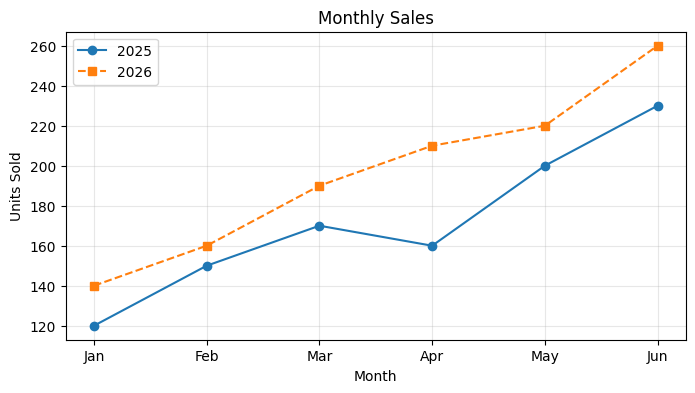

In [ ]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales_2025 = [120, 150, 170, 160, 200, 230]
sales_2026 = [140, 160, 190, 210, 220, 260]

plt.figure(figsize=(8, 4))                       # width, height in inches
plt.plot(months, sales_2025, marker="o", label="2025")
plt.plot(months, sales_2026, marker="s", linestyle="--", label="2026")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.legend()                                     # shows the labels
plt.grid(True, alpha=0.3)                        # light grid lines
plt.show()

### 3.2 Bar chart

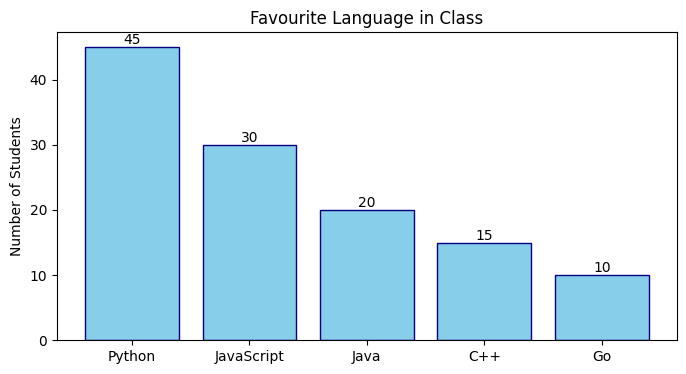

In [ ]:
languages = ["Python", "JavaScript", "Java", "C++", "Go"]
students = [45, 30, 20, 15, 10]

plt.figure(figsize=(8, 4))
bars = plt.bar(languages, students, color="skyblue", edgecolor="navy")
plt.bar_label(bars)                              # number on top of each bar
plt.title("Favourite Language in Class")
plt.ylabel("Number of Students")
plt.show()

### 3.3 Scatter plot
Each dot is one student. If the dots go up from left to right, more study hours tend to mean higher scores.

In [ ]:
np.random.seed(0)
study_hours = np.random.uniform(1, 10, 50)                         # 50 random students
exam_score = study_hours * 8 + np.random.normal(0, 5, 50) + 15     # score depends on hours + some noise

plt.figure(figsize=(6, 5))
plt.scatter(study_hours, exam_score, c=exam_score, cmap="viridis")  # colour by score
plt.colorbar(label="Score")
plt.title("Study Hours vs Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Score")
plt.show()

### 3.4 Several charts in one figure (subplots)
`plt.subplots(1, 2)` makes 1 row with 2 charts. We then draw on each one using `axes[0]` and `axes[1]`.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(np.random.normal(70, 10, 500), bins=20, color="salmon", edgecolor="white")
axes[0].set_title("Distribution of 500 Exam Scores")
axes[0].set_xlabel("Score")

axes[1].pie([40, 30, 20, 10], labels=["Python", "Web", "Data", "AI"],
            autopct="%1.0f%%", startangle=90)
axes[1].set_title("Course Enrolment")

plt.tight_layout()      # stops the charts overlapping
plt.show()

### 3.5 Plotting straight from pandas
DataFrames have a built-in `.plot()` method that uses Matplotlib behind the scenes.

In [ ]:
df.groupby("city")["revenue"].sum().plot(kind="bar", color="teal", figsize=(6, 4))
plt.title("Revenue by City")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.show()

### ✏️ Practice: Matplotlib
1. Make a line chart of the temperatures from the NumPy practice.
2. Give it a title and axis labels.
3. Bonus: make a bar chart of total quantity sold per product from `df`.

In [ ]:
# Write your answer here

---
# 4️⃣ Web Scraping – Collecting Data From Websites

**Web scraping** means writing code that reads a web page and pulls out the information we want. We use two libraries:
- **requests** downloads the page's HTML.
- **BeautifulSoup** searches the HTML for the parts we need.

We'll practise on **quotes.toscrape.com** and **books.toscrape.com**, which were built specially for scraping practice.

### 🤝 Scraping etiquette
1. Check the site's `robots.txt` file (e.g. `site.com/robots.txt`).
2. Read the Terms of Service, because some sites forbid scraping.
3. Add a pause between requests so you don't overload the server.
4. If the site offers an official **API**, use that instead.

### 4.1 Downloading a page
A **status code** of `200` means the download worked.

In [ ]:
url = "https://quotes.toscrape.com/"
response = requests.get(url, timeout=10)
print("Status code:", response.status_code)
print("First 300 characters of the HTML:\n")
print(response.text[:300])

### 4.2 Finding things in the HTML
How do we know what to search for? Open the website in Chrome, **right-click a quote → Inspect**. You'll see each quote is inside `<div class="quote">`, the text is in `<span class="text">` and the author in `<small class="author">`.

- `find()` gets the **first** match.
- `find_all()` gets **every** match.
- `get_text()` takes the text out of a tag.

In [ ]:
soup = BeautifulSoup(response.text, "html.parser")

for quote in soup.find_all("div", class_="quote"):
    text = quote.find("span", class_="text").get_text()
    author = quote.find("small", class_="author").get_text()
    tags = [tag.get_text() for tag in quote.find_all("a", class_="tag")]
    print(text)
    print("   -", author, tags, "\n")

### 4.3 Scraping many pages into a table
Now we scrape **3 pages of books**, collect them into a list of dictionaries, and turn that into a pandas DataFrame.

New tricks used here:
- `select()` / `select_one()` find elements using **CSS selectors** (`"p.price_color"` means a `<p>` tag with class `price_color`).
- `tag["title"]` reads an **attribute** of a tag.
- `time.sleep(1)` waits one second between pages to be polite.

In [ ]:
RATINGS = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}   # the site writes ratings as words
books = []

for page in range(1, 4):
    page_url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    print("Scraping", page_url)
    soup = BeautifulSoup(requests.get(page_url, timeout=10).text, "html.parser")

    for book in soup.select("article.product_pod"):
        title = book.h3.a["title"]                                      # attribute
        price = book.select_one("p.price_color").get_text()            # e.g. "£51.77"
        rating_word = book.select_one("p.star-rating")["class"][1]     # e.g. "Three"
        in_stock = "In stock" in book.select_one("p.availability").get_text()

        books.append({
            "title": title,
            "price": float(price.replace("£", "").replace("Â", "")),  # text -> number
            "rating": RATINGS[rating_word],
            "in_stock": in_stock,
        })

    time.sleep(1)   # be polite!

books_df = pd.DataFrame(books)
books_df.to_csv("books.csv", index=False)
print(f"\nScraped {len(books_df)} books ✅")
books_df.head()

---
# 5️⃣ Mini Project – Putting It All Together

We now use **all four libraries together**: the data we scraped (requests + BeautifulSoup) is analysed (pandas + NumPy) and drawn (Matplotlib). This is the same workflow real data analysts use.

In [ ]:
print("Average price: £", round(books_df["price"].mean(), 2))
print("Cheapest book :", books_df.loc[books_df["price"].idxmin(), "title"])
print("Priciest book :", books_df.loc[books_df["price"].idxmax(), "title"])

print("\nAverage price by star rating:")
books_df.groupby("rating")["price"].mean().round(2)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# How many books have each rating?
books_df["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="gold", edgecolor="black")
axes[0].set_title("Number of Books per Star Rating")
axes[0].set_xlabel("Stars")
axes[0].tick_params(axis="x", rotation=0)

# Does a higher rating mean a higher price?
axes[1].scatter(books_df["rating"], books_df["price"], alpha=0.6)
axes[1].plot(range(1, 6), books_df.groupby("rating")["price"].mean(), color="red", marker="o", label="Average")
axes[1].set_title("Price vs Rating")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Price (£)")
axes[1].legend()

plt.tight_layout()
plt.show()

### ✏️ Final Challenge
1. Change the scraper to collect **10 pages** instead of 3.
2. Scrape **all 10 pages of quotes.toscrape.com** into a DataFrame with `text`, `author` and `tags` columns.
3. Find the **top 5 authors** with the most quotes and draw a bar chart of them.

*Hint for page 2 onwards of the quotes site: `https://quotes.toscrape.com/page/2/`*

In [ ]:
# Write your answer here

---
## 🎉 Well done!
You've learned the basics of:
- **NumPy** – arrays and fast maths
- **Pandas** – tables, filtering and grouping
- **Matplotlib** – line, bar, scatter, histogram and pie charts
- **Web Scraping** – downloading pages and pulling out data

**Next steps:** try **seaborn** for prettier charts, or **scikit-learn** for your first machine-learning model.